# Поиск по смыслу: эмбеддинги

**Где это в решении.** Задача — для каждого тестового запроса выбрать 50 объявлений из корпуса. Корпус — это 189 212 объявлений из файла `benchmark_items.parquet`, ответы ищем только среди них. Тестовые запросы — 2 452 запроса из `benchmark_queries.parquet`, правильных ответов к ним у нас нет. Решение работает в два этапа. Сначала ретривер отбирает для запроса несколько сотен кандидатов. Потом реранкер (модель LightGBM) заново упорядочивает кандидатов и берёт первые 50. Первый источник кандидатов — BM25, поиск по словам из бейзлайна (`retrieval/baseline.ipynb`): объявление получает тем больше баллов, чем больше в нём слов запроса и чем эти слова реже. Этот ноутбук строит второй источник — поиск по смыслу.

**Зачем он нужен.** BM25 находит только объявления, в которых есть слова запроса. А в `processing/text.ipynb` видно, что у 4.9% пар «запрос — выбранное объявление» в выбранном объявлении нет ни одного слова запроса. Например, человек ищет «прокопать траншею», а выбирает объявление «Ручная копка земли». Такие объявления может найти только поиск по смыслу.

**Как он работает.** Нейросеть-эмбеддер превращает текст в вектор — список из нескольких сотен чисел — так, что у текстов с похожим смыслом векторы близки. Сколько чисел в векторе, зависит от модели (таблица в разделе 3), у выбранной модели их 1024. Близость измеряем косинусом угла между векторами: 1 — смысл совпадает, около 0 — тексты не связаны. Каждое объявление корпуса один раз превращаем в вектор. Для запроса считаем косинус его вектора с вектором каждого объявления и берём самые близкие объявления.

**Данные.** Train — обучающие данные задачи: 497 673 строки «поля поиска → выбранное объявление». Поля поиска — это текст, локация, фильтры, категория и флаг доставки. Номера запроса у строк нет, поэтому строки с одинаковыми полями поиска мы склеиваем в один запрос. В `validation/split.ipynb` train поделён на три части:

- **валидация**, или проверочные запросы, — 5 032 запроса из train, на них меряем качество (итоговый реранкер для ответа потом учится и на них, `ranking/dense.ipynb`);
- **обучение реранкера** — 6 487 запросов из train, на них учится LightGBM;
- **обучение ретривера** — всё остальное, 482 161 строка. По нему считаются доли выборов по локациям (что это — в разделе 3) и дообучается эмбеддер.

**Как меряем качество.** Recall@50 — доля правильных объявлений запроса, попавших в 50 ответов, усреднённая по проверочным запросам. Это метрика задачи. Recall@200 и Recall@1000 — то же для первых 200 и первых 1000 объявлений. Они показывают, годится ли поиск как источник кандидатов: правильное объявление, которое стоит, например, на 150-м месте, реранкер ещё может поднять в первые 50.

Код — `avito.embeddings`, запуск — скрипты из `scripts/embeddings`:

1. `prepare.py` — собирает тексты объявлений и запросов и обучающие пары, работает без видеокарты;
2. `encode.py` — превращает корпус и запросы в векторы готовыми моделями и считает Recall на валидации;
3. `finetune.py` — дообучает модель на парах из обучения ретривера, потом так же превращает тексты в векторы и считает Recall.

Шаги 2 и 3 нужно запускать на видеокарте. Их результаты (дообученная модель, векторы, метрики и лог обучения) лежат в архиве с артефактами, ссылка — в README. Здесь — что подавалось в модели, на чём учили и что получилось.

In [1]:
import json

import matplotlib.pyplot as plt
import polars as pl

from avito import paths
from avito.embeddings.load import DENSE_MODEL
from avito.embeddings.texts import normalize_spaces, query_text
from avito.ingestion import load as ingested
from avito.processing.params import clean_params
from avito.validation.load import load_ranker_queries, load_retriever_fold, load_val_queries

pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(200)
pl.Config.set_tbl_width_chars(220);

## 1. Какие тексты подаём в модель

Модель читает текст кусками слов — токенами. Мы ограничили текст для модели 256 токенами (примерно 150–200 слов): чем длиннее текст, тем дольше модель превращает его в вектор и тем дольше идёт обучение. Всё, что дальше 256 токенов, модель не видит. Поэтому текст объявления делаем коротким и плотным, а от описания берём только начало:

`заголовок. очищенные параметры. первые 700 символов описания`

**Очистка параметров** (`avito.processing.params`). Параметры — это склейка пар «ключ значение»: вид услуги, адрес, цены, график работы по дням. Для смысла полезны только значения ключей вроде «Вид услуги», «Тип услуги», «Услуга», «Чем вы занимаетесь». Всё остальное (адреса, цены, графики, «Работа по договору» и так далее) выбрасываем, иначе оно заняло бы весь лимит в 256 токенов. Пример одного объявления:

In [2]:
corpus = ingested.load_corpus(["item_id", "item_infm_params_text"])
example = corpus.row(0, named=True)["item_infm_params_text"]

print("ПАРАМЕТРЫ ДО ОЧИСТКИ:", example)
print()
print("ПОСЛЕ ОЧИСТКИ:", clean_params(example))

ПАРАМЕТРЫ ДО ОЧИСТКИ: Вид услуги Компьютерная помощь Место оказания услуг пр-т Ленина Тип стоимости за услугу Начальная цена График работы от 34200 График работы до 82800 Время работы, с 09:30 Время работы, до 23:00 Начальная цена Тип стоимости за услугу Стоимость 500 Услуга Диагностика компьютера Начальная цена Тип стоимости за услугу Стоимость 500 Услуга Начальная цена Тип стоимости за услугу Стоимость 500 Услуга Начальная цена Тип стоимости за услугу Стоимость 1000 Услуга Замена термопасты Начальная цена Тип стоимости за услугу Стоимость 1000 Услуга Ремонт после залития Начальная цена Тип стоимости за услугу Стоимость 500 Услуга Чистка системы охлаждения Начальная цена Тип стоимости за услугу Стоимость 500 Услуга Установка базовых драйверов Начальная цена Тип стоимости за услугу Стоимость 1000 Услуга Восстановление удалённых файлов Начальная цена Тип стоимости за услугу Стоимость 500 Услуга Установка антивируса Начальная цена Тип стоимости за услугу Стоимость 1000 Услуга Чистка и уд

Считаем по всему корпусу, сколько символов в параметрах объявления до очистки и после неё:

In [3]:
raw_lengths = corpus["item_infm_params_text"].str.len_chars()
clean_lengths = pl.Series([len(clean_params(text)) for text in corpus["item_infm_params_text"].to_list()])

pl.DataFrame({
    "показатель": ["символов в параметрах объявления в среднем", "символов после очистки в среднем", "доля выброшенных символов"],
    "значение": [raw_lengths.mean(), clean_lengths.mean(), 1 - clean_lengths.sum() / raw_lengths.sum()],
})

показатель,значение
str,f64
"""символов в параметрах объявления в среднем""",973.896872
"""символов после очистки в среднем""",165.33148
"""доля выброшенных символов""",0.830237


Очистка выбрасывает 83% символов параметров, и в тексте для модели остаётся в основном то, чем занимается исполнитель.

Кроме текста, пользователь может выбрать в поиске фильтры, например «Вид услуги Деловые услуги». Текст запроса для модели — сам запрос и его фильтры, очищенные так же, как параметры объявления: от фильтров остаются только значения вроде вида и типа услуги. Получается `текст запроса. очищенные фильтры`, например «обзвон по базе. Деловые услуги». Тексты собирает `scripts/embeddings/prepare.py`. Несколько готовых текстов объявлений (первые 400 символов):

In [4]:
documents = pl.read_parquet(paths.EMBEDDING_DOCUMENTS)
queries = pl.read_parquet(paths.EMBEDDING_QUERIES)
pairs = pl.read_parquet(paths.EMBEDDING_PAIRS)

for number, text in enumerate(documents.filter(pl.col("in_corpus")).sample(3, seed=0)["text"], start=1):
    print(f"ОБЪЯВЛЕНИЕ {number}:", text[:400])
    print()

ОБЪЯВЛЕНИЕ 1: Бурение скважин на воду под ключ. Сад, благоустройство; Скважины, септики, колодцы. Здравствуйте! Я Семен, специалист по бурению абиссинских скважин. Предлагаю надёжное решение для автономного водоснабжения вашего участка — без использования тяжёлой техники и с минимальным воздействием на территорию. Применяю ручной метод бурения: это позволяет работать даже в труднодоступных местах — в том числе 

ОБЪЯВЛЕНИЕ 2: Услуги сантехника сантехнические работы. Ремонт и отделка; Сантехника; Аварийный вызов сантехника; Устранение протечки; Прочистка канализации; Монтаж систем водоснабжения; Перенос труб ХВС и ГВС; Монтаж сантехнических труб; Монтаж канализации; Установка септиков; Монтаж наружной канализации; Монтаж труб отопления; Демонтаж труб отопления; Монтаж полотенцесушителя; Монтаж газовых котлов; Установка 

ОБЪЯВЛЕНИЕ 3: Стелы каменные в наличии. Памятники из гранита на могилу | Изготовление надгробий под ключ Изготовление памятников из гранита и мрамора — наша специализац

Тексты запросов готовим для трёх наборов: проверочных запросов (валидации), запросов для обучения реранкера и тестовых запросов. Векторы нужны для всех трёх. По проверочным запросам меряем качество. Для запросов реранкера считаем признаки — подсказки, по которым реранкер упорядочивает кандидатов. По тестовым запросам строим итоговый ответ. Сколько запросов в каждом наборе и примеры их текстов:

In [5]:
SET_NAMES = {"val": "валидация", "ranker": "обучение реранкера", "bench": "тестовые запросы"}

queries.group_by("set").agg(pl.len().alias("запросов"), pl.col("text").head(3).alias("примеры текстов")).with_columns(
    pl.col("set").replace_strict(SET_NAMES).alias("набор")
).select("набор", "запросов", "примеры текстов")

набор,запросов,примеры текстов
str,u32,list[str]
"""тестовые запросы""",2452,"[""перевозки владикавказ тбилиси"", ""обзвон по базе. Деловые услуги"", ""липоредукция подбородка. Красота, здоровье""]"
"""валидация""",5032,"[""грузоперевозки 24 часа"", ""реклама на заднем стекле"", ""канекалон плетение""]"
"""обучение реранкера""",6487,"[""установка забора из профнастила. Строительство"", ""электро эпиляция. Красота, здоровье"", ""прием металла""]"


## 2. На чём дообучаем

Обучающие пары «текст запроса → выбранное объявление» берём из обучения ретривера. Напомним, что это train без строк проверочных запросов и без строк запросов реранкера, 482 161 строка (`validation/split.ipynb`). Каждая строка — один выбор пользователя: что он искал и какое объявление выбрал. Одинаковые пары оставляем по одному разу, а на один текст запроса берём не больше 20 пар, чтобы частые запросы вроде «маникюр» не заняли всё обучение.

Для обучения нужны тексты всех объявлений из этих пар, а многие из них в корпус не входят: объявление из корпуса выбрано только в 6.6% строк train (`validation/split.ipynb`). Поэтому тексты собираем и для объявлений корпуса, и для объявлений из пар. А в векторы для поиска превращаем только объявления корпуса.

Чтобы видеть, сколько пар убирает каждый шаг, заново собираем из обучения ретривера все разные пары «текст запроса — выбранное объявление» так же, как это делает `prepare.py`, и сравниваем с готовыми обучающими парами:

In [6]:
fold = load_retriever_fold(["search_query", "search_infm_params_text", "item_id"])
fold_queries = fold.select("search_query", "search_infm_params_text").unique()
fold_queries = fold_queries.with_columns(
    pl.Series("query_text", [query_text(query, filters) for query, filters in zip(fold_queries["search_query"].to_list(), fold_queries["search_infm_params_text"].to_list())])
)
all_pairs = fold.join(fold_queries, on=["search_query", "search_infm_params_text"]).select("query_text", "item_id").unique()

pl.DataFrame({
    "показатель": [
        "строк в обучении ретривера",
        "разных пар «текст запроса — выбранное объявление»",
        "обучающих пар: не больше 20 на один текст",
        "разных текстов запросов в обучающих парах",
        "объявлений, для которых собран текст",
        "из них в корпусе (только их превращаем в векторы для поиска)",
    ],
    "значение": [fold.height, all_pairs.height, pairs.height, pairs["query_text"].n_unique(), documents.height, documents["in_corpus"].sum()],
})

показатель,значение
str,i64
"""строк в обучении ретривера""",482161
"""разных пар «текст запроса — выбранное объявление»""",444950
"""обучающих пар: не больше 20 на один текст""",253662
"""разных текстов запросов в обучающих парах""",93188
"""объявлений, для которых собран текст""",393554
"""из них в корпусе (только их превращаем в векторы для поиска)""",189212


Повторы убирают немного: из 482 161 строки остаётся 444 950 разных пар. Больше всего убирает ограничение в 20 пар на текст: после него остаётся 253 662 пары. Разных текстов запросов в них 93 188 — больше, чем разных текстов во всём train (74 529, `ingestion/insights.ipynb`). Так получается потому, что здесь текст запроса включает очищенные фильтры: один и тот же запрос с разными фильтрами даёт разные тексты.

**Не видела ли модель правильных ответов.** Если бы модель при обучении видела пару «текст проверочного запроса — его правильное объявление», Recall на валидации был бы завышен. Строк самих проверочных запросов в обучении нет. Но тот же текст мог встретиться в обучении с другой локацией и привести к тому же объявлению. Здесь «текст» — это текст запроса вместе с очищенными фильтрами, как его видит модель. Для каждого набора считаем две доли: сколько текстов запросов встречается в обучающих парах и сколько пар «текст — правильное объявление» есть среди обучающих пар:

In [7]:
seen_pairs = pairs.rename({"query_text": "text"}).with_columns(pl.lit(True).alias("seen"))
seen_texts = pairs.select(pl.col("query_text").alias("text")).unique()

rows = []
for name in ["val", "ranker", "bench"]:
    part = queries.filter(pl.col("set") == name)
    row = {
        "набор": SET_NAMES[name],
        "запросов": part.height,
        "доля текстов (вместе с фильтрами), которые модель видела при обучении": part.join(seen_texts, on="text", how="semi").height / part.height,
        "доля пар «текст с фильтрами — правильное объявление», которые модель видела": None,
    }
    if name != "bench":
        relevant = part.select("text", pl.col("relevant_item_ids").alias("item_id")).explode("item_id", empty_as_null=True)
        relevant = relevant.join(seen_pairs, on=["text", "item_id"], how="left")
        row["доля пар «текст с фильтрами — правильное объявление», которые модель видела"] = relevant["seen"].fill_null(False).mean()
    rows.append(row)

pl.DataFrame(rows)

набор,запросов,"доля текстов (вместе с фильтрами), которые модель видела при обучении","доля пар «текст с фильтрами — правильное объявление», которые модель видела"
str,i64,f64,f64
"""валидация""",5032,0.320747,0.005499
"""обучение реранкера""",6487,0.887776,0.012224
"""тестовые запросы""",2452,0.277732,null


При точном совпадении текста вместе с фильтрами модель видела 0.55% пар «текст — правильное объявление» валидации и 1.2% таких пар у запросов реранкера. У тестовых запросов правильных ответов нет, поэтому для них считаем только тексты.

Но так не учтён случай, когда тот же запрос встречался в обучении с другими фильтрами: тогда тексты для модели разные, хотя сам запрос тот же. Поэтому считаем ещё раз и сравниваем только текст запроса, без фильтров. Здесь же показываем, у какой доли запросов после очистки вообще остаются фильтры:

In [8]:
query_only = fold_queries.select(
    "query_text",
    pl.Series("query_only", [normalize_spaces(query) for query in fold_queries["search_query"].to_list()]),
).unique()
seen_query_pairs = pairs.join(query_only, on="query_text").select("query_only", "item_id").unique().with_columns(pl.lit(True).alias("seen"))

rows = []
for name, part in [("val", load_val_queries()), ("ranker", load_ranker_queries())]:
    relevant = part.select(
        pl.Series("query_only", [normalize_spaces(query) for query in part["search_query"].to_list()]),
        pl.col("relevant_item_ids").alias("item_id"),
    ).explode("item_id", empty_as_null=True)
    relevant = relevant.join(seen_query_pairs, on=["query_only", "item_id"], how="left")
    rows.append({
        "набор": SET_NAMES[name],
        "доля запросов, у которых после очистки остались фильтры": pl.Series([clean_params(filters) != "" for filters in part["search_infm_params_text"].to_list()]).mean(),
        "доля пар «текст без фильтров — правильное объявление», которые модель видела": relevant["seen"].fill_null(False).mean(),
    })

pl.DataFrame(rows)

набор,"доля запросов, у которых после очистки остались фильтры","доля пар «текст без фильтров — правильное объявление», которые модель видела"
str,f64,f64
"""валидация""",0.440779,0.010605
"""обучение реранкера""",0.541236,0.029161


Фильтры после очистки остаются у 44% проверочных запросов и у 54% запросов реранкера. Если фильтры не учитывать, модель видела 1.1% правильных пар валидации и 2.9% правильных пар запросов реранкера. Это больше, чем при точном совпадении, но в любом случае правильные ответы почти не попали в обучение. Значит, Recall эмбеддера на валидации не завышен тем, что модель заучила ответы, а признаки эмбеддера на запросах реранкера почти не подсказывают ему правильный ответ.

**Тексты запросов реранкера модель видела гораздо чаще.** Речь не о парах с правильными объявлениями, а о самих текстах. 89% текстов запросов реранкера встречаются в обучающих парах (с другими объявлениями), а у валидации таких текстов 32%, у теста — 28% (таблица проверки для трёх наборов выше). Причина в разбиении: в валидацию взяли почти все запросы с «новыми» текстами (такими, которые встречаются в train только в одном запросе), если все выбранные по ним объявления лежат в корпусе. Поэтому у запросов реранкера 97% текстов встречаются в train ещё раз (`validation/split.ipynb`). На знакомых текстах эмбеддер, вероятно, работает лучше, чем будет работать на тесте, но отдельно мы это не проверяли. Если это так, реранкер, обученный только на таких запросах, может слишком доверять эмбеддеру. Что мы с этим делаем — в `ranking/dense.ipynb`, раздел 5.

## 3. Готовые модели

Сначала пробуем готовые открытые модели без дообучения. Все они взяты с HuggingFace — сайта, где выкладывают открытые нейросети. Это многоязычные модели, которые понимают русский: три модели e5 от intfloat, bge-m3 от BAAI и USER-bge-m3 от deepvk — версия bge-m3, доученная для русского языка. У e5 base и large — маленькая и большая версии, instruct — версия, которой перед запросом пишут короткую инструкцию, что нужно найти (у нас — объявления об услугах по поисковому запросу).

Объявления упорядочиваем по той же формуле, что и в бейзлайне (`retrieval/baseline.ipynb`), только вместо оценки BM25 берём косинус:

`оценка = косинус / максимальный косинус по запросу + alpha · log(доля выборов локации объявления + 0.0003)`

Что здесь что:

- **Доли выборов по локациям** считаем по обучению ретривера: для каждой локации поиска — в каких локациях и как часто выбирали объявления. Например, при поиске по «Москве и области» 60% выборов приходится на саму Москву (`retrieval/baseline.ipynb`). «Доля выборов локации объявления» в формуле — это такая доля для пары «локация поиска — локация объявления».
- Косинус делим на максимальный косинус по запросу, чтобы у лучшего объявления каждого запроса было 1 и прибавка за локацию весила одинаково для всех запросов.
- Логарифм нужен, чтобы разница между 50% и 5% значила столько же, сколько между 5% и 0.5%. Добавка 0.0003 нужна для локаций, где при таком поиске ни разу не выбирали: без неё логарифм был бы минус бесконечностью, а с ней их объявления сильно опускаются, но не выбрасываются совсем.
- `alpha` — вес локации: чем он больше, тем сильнее поднимаются объявления из тех мест, где обычно выбирают.

Пробуем alpha 0, 0.01, 0.02, 0.05 и 0.1 и для каждой модели берём лучший. Лучший alpha выбираем на тех же проверочных запросах, на которых потом сравниваем модели (в бейзлайне alpha выбран так же), поэтому лучшие числа могут быть немного завышены. Для каждой модели показываем, сколько чисел в её векторе, лучший alpha и Recall на валидации при нём. Строка «дообученная» — та же модель после дообучения из раздела 4, она здесь для сравнения. Метрики каждой модели лежат в `data/embeddings/output/<модель>/metrics.json`.

In [9]:
HF_IDS = {
    "e5-base": "intfloat/multilingual-e5-base",
    "e5-large": "intfloat/multilingual-e5-large",
    "e5-large-instruct": "intfloat/multilingual-e5-large-instruct",
    "bge-m3": "BAAI/bge-m3",
    "user-bge-m3": "deepvk/USER-bge-m3",
    DENSE_MODEL: "intfloat/multilingual-e5-large-instruct, дообученная",
}

VECTOR_SIZES = {
    "e5-base": 768,
    "e5-large": 1024,
    "e5-large-instruct": 1024,
    "bge-m3": 1024,
    "user-bge-m3": 1024,
    DENSE_MODEL: 1024,
}

metrics = []
for path in sorted(paths.EMBEDDINGS_OUTPUT_DIR.glob("*/metrics.json")):
    for row in json.loads(path.read_text()):
        metrics.append({"model": path.parent.name, "vector_size": VECTOR_SIZES[path.parent.name]} | row)
metrics = pl.DataFrame(metrics).with_columns(pl.col("model").replace_strict(HF_IDS).alias("модель"))

best = metrics.sort("recall@50", descending=True).unique("model", keep="first").sort("recall@50", descending=True)
best.select(
    "модель",
    pl.col("vector_size").alias("чисел в векторе"),
    pl.col("alpha").alias("лучший alpha"),
    pl.col("recall@50").alias("Recall@50"),
    pl.col("recall@200").alias("Recall@200"),
    pl.col("recall@1000").alias("Recall@1000"),
)

модель,чисел в векторе,лучший alpha,Recall@50,Recall@200,Recall@1000
str,i64,f64,f64,f64,f64
"""intfloat/multilingual-e5-large-instruct, дообученная""",1024,0.05,0.894376,0.964361,0.991256
"""intfloat/multilingual-e5-large-instruct""",1024,0.01,0.857015,0.946509,0.981121
"""intfloat/multilingual-e5-large""",1024,0.01,0.839825,0.93389,0.97655
"""BAAI/bge-m3""",1024,0.05,0.820085,0.914448,0.96244
"""deepvk/USER-bge-m3""",1024,0.05,0.816706,0.911268,0.96254
"""intfloat/multilingual-e5-base""",768,0.01,0.804981,0.911798,0.96413


Для сравнения на графике — бейзлайн (`retrieval/baseline.ipynb`): BM25 с долями выборов по локациям и он же с фильтрами. «С фильтрами» значит, что к оценке BM25 по словам запроса прибавляется с весом 0.3 оценка BM25 по словам фильтров, например «Вид услуги Красота, здоровье».

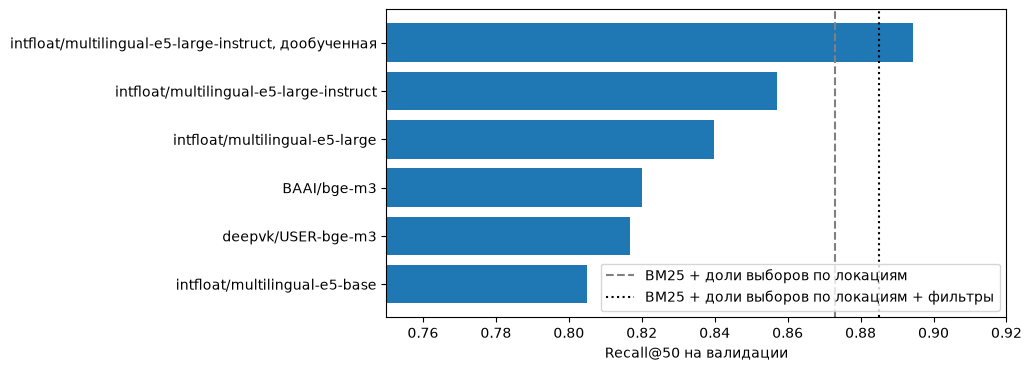

In [10]:
BM25_PRIOR = 0.873
BM25_PRIOR_FILTERS = 0.885

plt.figure(figsize=(8, 4))
plt.barh(best["модель"].to_list()[::-1], best["recall@50"].to_list()[::-1])
plt.axvline(BM25_PRIOR, color="gray", linestyle="--", label="BM25 + доли выборов по локациям")
plt.axvline(BM25_PRIOR_FILTERS, color="black", linestyle=":", label="BM25 + доли выборов по локациям + фильтры")
plt.xlim(0.75, 0.92)
plt.xlabel("Recall@50 на валидации")
plt.legend(loc="lower right")
plt.show()

Готовые модели без дообучения хуже BM25: лучшая, `intfloat/multilingual-e5-large-instruct`, даёт Recall@50 = 0.857 против 0.873 у BM25 с долями выборов по локациям. Её и дообучаем.

Как Recall@50 на валидации зависит от веса локации alpha — у этой модели до и после дообучения:

In [11]:
alpha_table = metrics.filter(pl.col("model").is_in(["e5-large-instruct", DENSE_MODEL])).pivot(
    on="model", index="alpha", values="recall@50"
).sort("alpha")
alpha_table.select(
    pl.col("alpha").alias("вес локации alpha"),
    pl.col("e5-large-instruct").alias("Recall@50 до дообучения"),
    pl.col(DENSE_MODEL).alias("Recall@50 после дообучения"),
)

вес локации alpha,Recall@50 до дообучения,Recall@50 после дообучения
f64,f64,f64
0.0,0.388646,0.426802
0.01,0.857015,0.694522
0.02,0.840819,0.820913
0.05,0.824523,0.894376
0.1,0.818661,0.886626


Без долей выборов по локациям (alpha = 0) поиск по смыслу почти бесполезен: Recall@50 около 0.4. Косинус ничего не знает о том, где искал человек, и модель предлагает подходящие по смыслу объявления со всей страны. Тот же вывод был и для BM25.

После дообучения лучший alpha больше: 0.05 вместо 0.01. Вероятно, после дообучения косинус у подходящих объявлений стал заметно выше, чем у неподходящих, то есть разница между ними выросла. Прибавка за локацию должна быть сравнима с этой разницей, иначе она почти ничего не меняет, поэтому нужен больший вес. При alpha = 0.01 дообученная модель даёт только 0.69.

## 4. Дообучение

Дообучаем `intfloat/multilingual-e5-large-instruct` на 253 662 парах «текст запроса → выбранное объявление» из раздела 2 (библиотека sentence-transformers).

**Как учится модель.** Пары идут пачками по 256. Для каждого запроса в пачке правильный ответ — его объявление, а 255 объявлений из остальных пар пачки считаются неправильными. Модель учится делать вектор запроса ближе к вектору своего объявления, чем к векторам 255 чужих (функция потерь `CachedMultipleNegativesRankingLoss`). Внутри одной пачки тексты запросов не повторяются, иначе объявление другой пары с тем же запросом ошибочно считалось бы неправильным.

**Параметры.** Шаг обучения — одна пачка из 256 пар. Делаем один проход по всем парам, это 990 шагов. Скорость обучения 0.00002 задаёт, насколько сильно меняются веса модели за один шаг; первые 5% шагов она плавно растёт от нуля. Веса модели на HuggingFace хранятся в половинной точности (fp16, числа с меньшим количеством знаков). Если учить прямо в ней, ошибка не снижается и модель ничему не учится. Поэтому перед обучением веса переводим в обычную точность (fp32), а сохраняем снова в fp16. На видеокарте RTX 4090 обучение заняло 38 минут.

**Кривая обучения.** Ошибка (loss) — среднее за последние 50 шагов: чем она меньше, тем увереннее модель отличает своё объявление от 255 чужих. Если бы модель угадывала наугад, ошибка была бы ln 256 ≈ 5.5. Лог сохраняет `scripts/embeddings/finetune.py`.

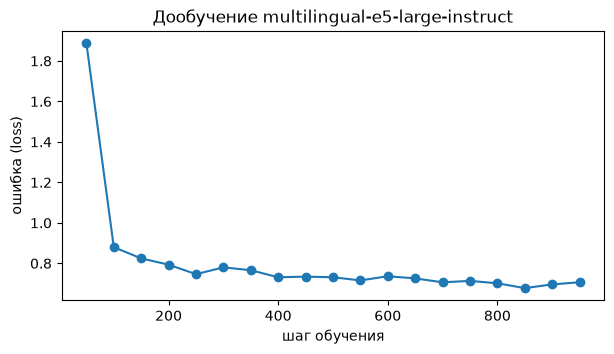

In [12]:
history = json.loads((paths.EMBEDDINGS_LOGS_DIR / f"{DENSE_MODEL}.json").read_text())
steps = [entry for entry in history if "loss" in entry]

plt.figure(figsize=(7, 3.5))
plt.plot([entry["step"] for entry in steps], [entry["loss"] for entry in steps], marker="o")
plt.xlabel("шаг обучения")
plt.ylabel("ошибка (loss)")
plt.title("Дообучение multilingual-e5-large-instruct")
plt.show()

Та же ошибка числами на нескольких шагах:

In [13]:
pl.DataFrame(steps).filter(pl.col("step").is_in([50, 100, 150, 500, 950])).select(
    pl.col("step").alias("шаг обучения"),
    pl.col("loss").alias("средняя ошибка за последние 50 шагов"),
)

шаг обучения,средняя ошибка за последние 50 шагов
i64,f64
50,1.888
100,0.8797
150,0.8244
500,0.7311
950,0.7065


Уже в среднем за первые 50 шагов ошибка 1.9 — намного ниже 5.5. Вероятно, готовая модель и до дообучения неплохо отличала своё объявление от чужих (ошибку до первого шага лог не записывает). За следующие 50 шагов ошибка падает до 0.9, а за оставшиеся 850 шагов — только до 0.7. Почти весь выигрыш дают первые 100 шагов, поэтому второй проход по тем же парам, вероятно, дал бы немного.

## Итог

- Готовые модели без дообучения хуже BM25: лучшая даёт Recall@50 = 0.857 против 0.873 у BM25 с долями выборов по локациям.
- Дообученная модель даёт Recall@50 = 0.894 (alpha = 0.05) — на уровне бейзлайна, BM25 с долями выборов по локациям и фильтрами (0.885). Разница — 0.009, то есть 0.9 п.п. (процентного пункта), но её 95% интервал [0.0001, 0.0189] почти касается нуля (`ranking/dense.ipynb`), так что в первых 50 два поиска почти равны.
- Глубже в списке поиск по смыслу находит больше правильных объявлений: Recall@200 = 0.964 против 0.947 у бейзлайна, Recall@1000 = 0.991 против 0.980 (`retrieval/baseline.ipynb`). Объединение первых 500 BM25 и первых 200 поиска по смыслу содержит 98.8% правильных объявлений против 96.9% у одних первых 500 BM25 (`ranking/dense.ipynb`). Значит, поиск по смыслу находит правильные объявления, которых нет в первых 500 BM25, и годится как второй источник кандидатов.
- Правильные ответы валидации в обучение почти не попали: 0.55% пар при точном совпадении текста вместе с фильтрами и 1.1%, если фильтры не учитывать.
- Сами тексты запросов реранкера модель видела при обучении гораздо чаще, чем тексты валидации и теста: 89% против 32% и 28%.
- Дообученная модель и её векторы корпуса и запросов лежат в `data/embeddings/models/e5-large-instruct-finetuned` и `data/embeddings/output/e5-large-instruct-finetuned`. Дальше первые 200 объявлений поиска по смыслу добавляются к первым 500 BM25 как кандидаты, а косинус и место объявления в списке поиска по смыслу становятся признаками для реранкера (`ranking/dense.ipynb`).